# 03 · Two-spin coupling search at L = 9

This notebook looks for nearest-neighbour two-spin couplings that lower the block ETH metric $\Phi(l)$ (defined in notebook 01) below its value at the PRX point of the mixed-field Ising model. Throughout: $L = 9$, blocks of $l + 1 = 4$ spins, and the middle 50 % of the spectrum.

**Canonical model.** All searches use

$$H(x) = J\sum_i Z_iZ_{i+1} + \sum_i Z_i + 0.25\,Z_0 - 0.25\,Z_{L-1} + \sum_{c} x_c \sum_i O^{(c)}_{i,i+1},$$

with $c \in \{XX,\ YY,\ XY{+}YX,\ XZ{+}ZX,\ YZ{+}ZY\}$ and $x = [J, c_{XX}, c_{YY}, c_{XY+YX}, c_{XZ+ZX}, c_{YZ+ZY}]$. This removes two exact invariances of $\Phi$. A uniform rotation about Y removes the X field ($g = 0$). Since $\Phi$ is scale invariant, the Z field can be set to 1. A ZZ coupling is left out because it is the same as $J$. The PRX point $(g, h) = (1.08, 0.30)$ maps to $J \approx 0.0639$, $c_{XX} \approx 0.8282$, $c_{XZ+ZX} \approx -0.2301$. It matches the MFIM up to the edge fields, which are not rotated.

**Standard frame.** $\Phi$ is also invariant under a uniform rotation about Z, which mixes (XX, YY, XY+YX) and (XZ+ZX, YZ+ZY). Results are quoted in the standard frame $c_{YZ+ZY} = 0$, $c_{XZ+ZX} > 0$.

**Two minima.**
* **Min 1 (Newton):** L-BFGS-B over all six parameters, seeded at the PRX point, with Hessian checks and one refinement (§3–5).
* **Min 2 (DE):** differential evolution over the five couplings with $J$ fixed at $J_\mathrm{PRX}$ (§6–7).

Notebook 04 checks both minima further.

> **Approaches tried earlier.** Earlier versions of this search (not kept) included:
> * A gradient line search that combined all six couplings from the single-coupling scans.
> * A 7D Newton search over $J$ and all six couplings, started from the best single-coupling point. It ended in the wrong basin because $J_\mathrm{PRX} \approx 0.064$ lies below the scanned range $J \in [0.3, 6]$.
> * Global DE searches over the full 8D space $[J, g, h, \text{couplings}]$, then with $g = 0$, then with $g = 0$ and $h = 1$.
>
> Each step removed one exact degeneracy of $\Phi$, which led to the canonical parametrization above.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from spin_eth import COUPLINGS, J_PRX, PARAMS, CanonicalModel, prx_canonical_point, to_standard_frame
from spin_eth.analysis import describe_modes, fd_hessian, grid_argmin, n_negative, scan_plane
from spin_eth.io import load_json, save_json
from spin_eth.operators import TWO_SITE_TERMS
from spin_eth.plotting import plot_mode_scan
from spin_eth.search import RecordingObjective, lbfgs, minimize_with_saddle_escape, run_de

RESULTS, FIGURES = Path("../results"), Path("../figures")
FIGURES.mkdir(exist_ok=True)
L, l = 9, 3
model = CanonicalModel(L, l)                         # x = [J, XX, YY, XY+YX, XZ+ZX, YZ+ZY]
ALL_COUPLINGS = tuple(TWO_SITE_TERMS)                # also ZZ, for the single-coupling scans
scan_model = CanonicalModel(L, l, couplings=ALL_COUPLINGS)

phi_prx = model.phi_mfim()
print(f"L={L}, l={l}, middle 50% of the spectrum:  Phi(PRX) = {phi_prx:.6e}")

L=9, l=3, middle 50% of the spectrum:  Phi(PRX) = 9.813847e-02


## 1. One coupling at a time

Each coupling $O$ is added on its own: $H = J\,ZZ + Z + \text{edge} + c\,O$. A $23 \times 33$ grid over $(J, c)$ locates the best $(J^*, c^*)$, and a finer 1D scan in $c$ at $J^*$ follows. No value of $J$ is assumed in advance. The PRX optimum has its field tilted about 75° from Z, so its $h$ has no direct meaning in this family. Because a ZZ coupling only shifts $J$, the ZZ row is a consistency check.

In [2]:
J_grid = np.linspace(0.3, 6.0, 23)
c_grid = np.linspace(-4.0, 4.0, 33)
c_fine = np.linspace(-4.0, 4.0, 81)
ic0, ic0_fine = np.argmin(np.abs(c_grid)), np.argmin(np.abs(c_fine))


def phi_single(J, name, c):
    return scan_model.phi_of(scan_model.single_coupling_hamiltonian(J, name, c))


single = {}
for name in ALL_COUPLINGS:
    grid = np.array([[phi_single(J, name, c) for c in c_grid]
                     for J in tqdm(J_grid, desc=f"2D scan {name}", leave=False)])
    iJ, ic = np.unravel_index(np.argmin(grid), grid.shape)
    iJ0 = np.argmin(grid[:, ic0])
    profile = np.array([phi_single(J_grid[iJ], name, c) for c in c_fine])
    single[name] = dict(grid=grid, J_opt=J_grid[iJ], c_opt=c_grid[ic], phi_opt=grid[iJ, ic],
                        J_opt_c0=J_grid[iJ0], phi_opt_c0=grid[iJ0, ic0], profile=profile)

table = pd.DataFrame([
    {"coupling": name, "J* (2D)": r["J_opt"], "c* (2D)": r["c_opt"],
     "Phi(c=0) best J": r["phi_opt_c0"], "Phi best": r["phi_opt"], "gain": r["phi_opt_c0"] / r["phi_opt"],
     "c* (1D)": c_fine[np.argmin(r["profile"])], "Phi best (1D)": r["profile"].min(),
     "gain (1D)": r["profile"][ic0_fine] / r["profile"].min()}
    for name, r in single.items()]).set_index("coupling")
f3, e4, x4 = "{:.3f}".format, "{:.4e}".format, "{:.4f}x".format
print(table.to_string(formatters={"J* (2D)": f3, "c* (2D)": f3, "Phi(c=0) best J": e4, "Phi best": e4,
                                  "gain": x4, "c* (1D)": f3, "Phi best (1D)": e4, "gain (1D)": x4}))

2D scan XX:   0%|          | 0/23 [00:00<?, ?it/s]

2D scan YY:   0%|          | 0/23 [00:00<?, ?it/s]

2D scan ZZ:   0%|          | 0/23 [00:00<?, ?it/s]

2D scan XY+YX:   0%|          | 0/23 [00:00<?, ?it/s]

2D scan XZ+ZX:   0%|          | 0/23 [00:00<?, ?it/s]

2D scan YZ+ZY:   0%|          | 0/23 [00:00<?, ?it/s]

         J* (2D) c* (2D) Phi(c=0) best J   Phi best     gain c* (1D) Phi best (1D) gain (1D)
coupling                                                                                    
XX         1.077   3.000      1.6732e+00 8.6370e-02 19.3725x   3.100    8.5334e-02  20.2204x
YY         1.077   3.000      1.6732e+00 8.6370e-02 19.3725x   3.100    8.5334e-02  20.2204x
ZZ         0.300   3.500      1.6732e+00 1.6732e+00  1.0000x   3.500    1.6732e+00   1.0266x
XY+YX      4.186  -4.000      1.6732e+00 2.5295e-01  6.6147x  -4.000    2.5295e-01   6.6147x
XZ+ZX      0.300  -1.500      1.6732e+00 9.0492e-02 18.4901x   1.600    9.0395e-02  19.0016x
YZ+ZY      0.300  -1.500      1.6732e+00 9.0492e-02 18.4901x  -1.600    9.0395e-02  19.0016x


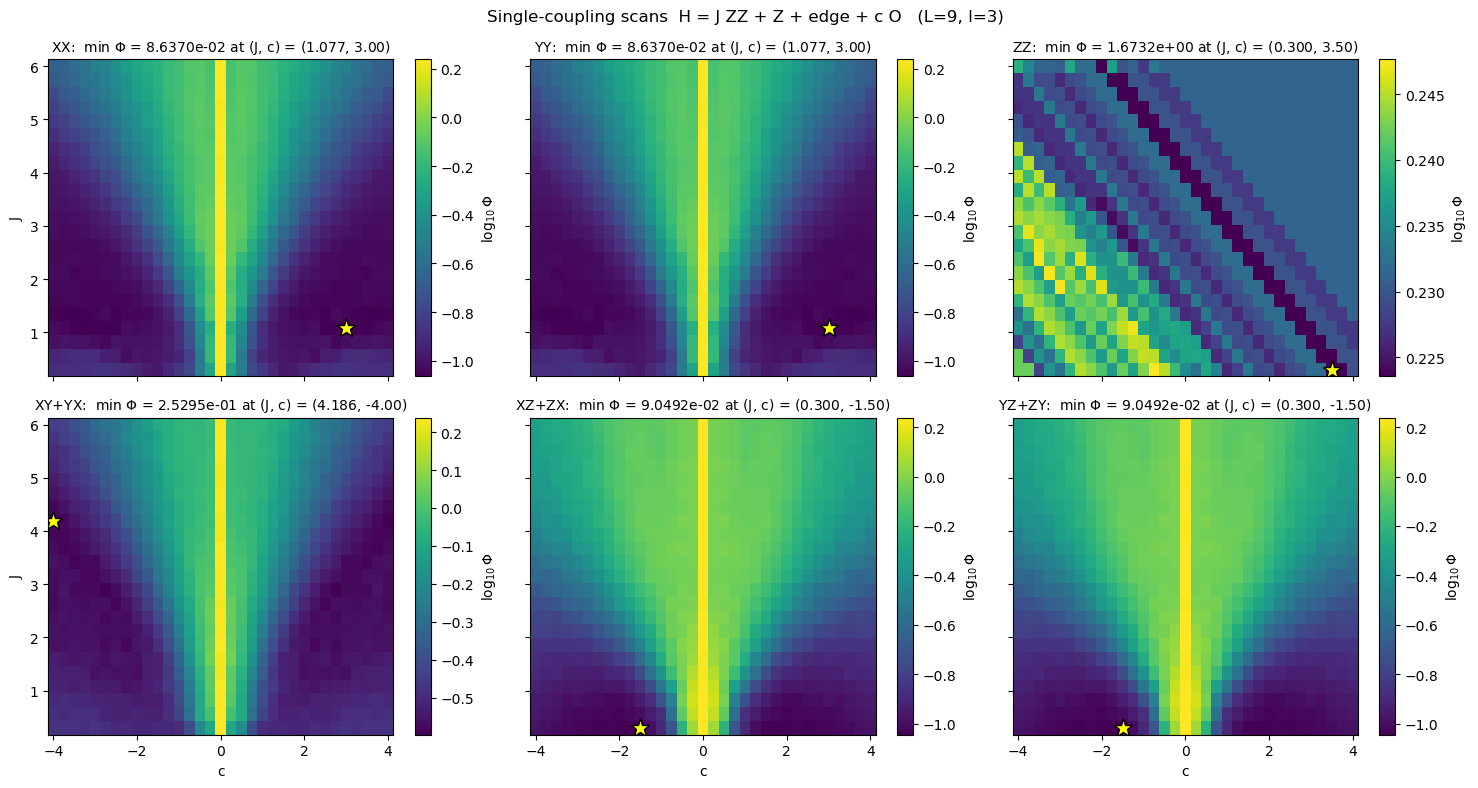

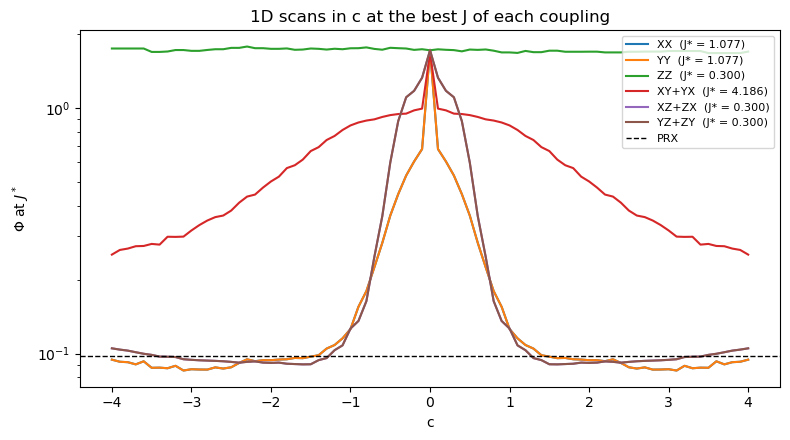

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for ax, (name, r) in zip(axes.flat, single.items()):
    im = ax.pcolormesh(c_grid, J_grid, np.log10(r["grid"]), shading="auto", cmap="viridis")
    ax.plot(r["c_opt"], r["J_opt"], "*", color="yellow", ms=14, mec="black")
    ax.set_title(f"{name}:  min $\\Phi$ = {r['phi_opt']:.4e} at (J, c) = ({r['J_opt']:.3f}, {r['c_opt']:.2f})", fontsize=10)
    fig.colorbar(im, ax=ax, label=r"$\log_{10}\Phi$")
for ax in axes[-1]:
    ax.set_xlabel("c")
for ax in axes[:, 0]:
    ax.set_ylabel("J")
fig.suptitle(f"Single-coupling scans  H = J ZZ + Z + edge + c O   (L={L}, l={l})")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, r in single.items():
    ax.semilogy(c_fine, r["profile"], label=f"{name}  (J* = {r['J_opt']:.3f})")
ax.axhline(phi_prx, color="k", ls="--", lw=1, label="PRX")
ax.set_xlabel("c")
ax.set_ylabel(r"$\Phi$ at $J^*$")
ax.set_title("1D scans in c at the best J of each coupling")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "L9_single_coupling_1d.png", dpi=110, bbox_inches="tight")
plt.show()

XX and YY give identical scans, and so do XZ+ZX and YZ+ZY. A 90° rotation about Z maps one onto the other and leaves $J\,ZZ + Z + \text{edge}$ unchanged.

## 2. Absolute Φ: a coupling on top of PRX vs the new family

Improvement ratios are only comparable against a common baseline. With $c = 0$, $H = J\,ZZ + Z + \text{edge}$ has no transverse field and is close to integrable. Its $\Phi$ is about 17× the PRX value, so ratios measured from it look inflated. The four points below are therefore compared in absolute $\Phi$:

* **A:** the PRX MFIM.
* **B:** PRX plus the best single coupling from a 1D scan.
* **C:** the best $c = 0$ point of the new family.
* **D:** its best single-coupling point.

In [4]:
H_A = model.mfim_hamiltonian()
phi_A = model.phi_of(H_A)
phi_B, label_B = phi_A, "none"
for name in tqdm(COUPLINGS, desc="PRX + one coupling", leave=False):
    for c in np.linspace(-3.0, 3.0, 61):
        val = model.phi_of(H_A + c * model.coupling_ops[name])
        if val < phi_B:
            phi_B, label_B = val, f"{name}, c={c:.2f}"

best = min(ALL_COUPLINGS, key=lambda name: single[name]["phi_opt"])
r = single[best]
phi_C = scan_model.phi_of(r["J_opt_c0"] * scan_model.H_zz + scan_model.H_z + scan_model.H_edge)
phi_D = r["phi_opt"]

print(f"A  PRX MFIM (g=1.08, h=0.30)          Phi = {phi_A:.6e}")
print(f"B  PRX + {label_B:<28}Phi = {phi_B:.6e}   (A/B = {phi_A / phi_B:.4f}x)")
print(f"C  J ZZ + Z, c=0 (J={r['J_opt_c0']:.3f})          Phi = {phi_C:.6e}   (C/A = {phi_C / phi_A:.2f}x)")
print(f"D  {best}, J={r['J_opt']:.3f}, c={r['c_opt']:.3f}          Phi = {phi_D:.6e}   (C/D = {phi_C / phi_D:.4f}x)")
print(f"\nD vs B (one coupling each): D/B = {phi_D / phi_B:.4f}x  ->  {'new family (D)' if phi_D < phi_B else 'PRX + coupling (B)'} is lower")

PRX + one coupling:   0%|          | 0/5 [00:00<?, ?it/s]

A  PRX MFIM (g=1.08, h=0.30)          Phi = 9.813847e-02
B  PRX + XY+YX, c=-0.50              Phi = 7.420719e-02   (A/B = 1.3225x)
C  J ZZ + Z, c=0 (J=3.927)          Phi = 1.673203e+00   (C/A = 17.05x)
D  XX, J=1.077, c=3.000          Phi = 8.637003e-02   (C/D = 19.3725x)

D vs B (one coupling each): D/B = 1.1639x  ->  PRX + coupling (B) is lower


## 3. Min 1: Newton search from the PRX point

The seed is the PRX point in canonical coordinates. One extra coupling is set first: $c_{XY+YX}$, which is zero at PRX and was also the coupling that helped most on top of the PRX MFIM in §2, takes its best value from a 1D scan. L-BFGS-B is then alternated with a full $6 \times 6$ finite-difference Hessian (step 0.06) until no eigenvalue is negative. At a saddle point the search would be kicked along the softest mode.

In [5]:
x_prx = prx_canonical_point()
phi_prx_canonical = model.phi(x_prx)
print("PRX point in the canonical frame:  " + ", ".join(f"{n}={v:+.4f}" for n, v in zip(PARAMS, x_prx)))
print(f"  Phi, MFIM (direct)   = {phi_prx:.6e}")
print(f"  Phi, canonical frame = {phi_prx_canonical:.6e}   "
      f"({abs(phi_prx_canonical - phi_prx) / phi_prx:.2%} difference from the unrotated edge fields)")

J0, cXX0, cXZ0 = x_prx[0], x_prx[1], x_prx[4]
H_seed = (J0 * model.H_zz + model.H_z + model.H_edge
          + cXX0 * model.coupling_ops["XX"] + cXZ0 * model.coupling_ops["XZ+ZX"])
c_scan = np.linspace(-3.0, 3.0, 61)
phi_scan = np.array([model.phi_of(H_seed + c * model.coupling_ops["XY+YX"])
                     for c in tqdm(c_scan, desc="XY+YX scan", leave=False)])
c_xy = c_scan[np.argmin(phi_scan)]
x0 = np.array([J0, cXX0, 0.0, c_xy, cXZ0, 0.0])
print(f"\nBest c_XY+YX at the PRX point: {c_xy:.3f}  ->  Phi = {phi_scan.min():.6e} ({phi_prx / phi_scan.min():.4f}x vs PRX)\n")

newton = minimize_with_saddle_escape(model.phi, x0)
x_newton, phi_newton = newton["x"], newton["fun"]

PRX point in the canonical frame:  J=+0.0639, XX=+0.8282, YY=+0.0000, XY+YX=+0.0000, XZ+ZX=-0.2301, YZ+ZY=+0.0000
  Phi, MFIM (direct)   = 9.813847e-02
  Phi, canonical frame = 9.951060e-02   (1.40% difference from the unrotated edge fields)


XY+YX scan:   0%|          | 0/61 [00:00<?, ?it/s]


Best c_XY+YX at the PRX point: 0.200  ->  Phi = 9.680258e-02 (1.0138x vs PRX)

Pass 1: L-BFGS-B  (start Phi = 9.680258e-02)


  converged: Phi = 7.326194e-02  (success=True)


  Hessian eigenvalues: +5.494e-01  +7.762e-01  +1.166e+00  +1.264e+00  +1.281e+00  +1.808e+00
  all eigenvalues positive: local minimum


In [6]:
x_newton_std, rot = to_standard_frame(x_newton)
x0_std, _ = to_standard_frame(x0)
c = x_newton_std[1:]
print(f"Newton result: Phi = {phi_newton:.6e}  ({phi_prx / phi_newton:.4f}x vs PRX)")
print(f"Standard frame (rotated {np.degrees(rot):.1f} deg about Z), seed -> optimum:")
for n, v0, v in zip(PARAMS, x0_std, x_newton_std):
    print(f"  {n:>6}: {v0:+.4f} -> {v:+.4f}")
print("Z-rotation invariants:")
print(f"  c_XX + c_YY             = {c[0] + c[1]:+.4f}")
print(f"  |c_XZ+ZX, c_YZ+ZY|      = {np.hypot(c[3], c[4]):.4f}")
print(f"  (c_XX - c_YY)^2 + c_XY^2 = {(c[0] - c[1])**2 + c[2]**2:.4f}")

# 5x5 Hessian over [J, XX, YY, XY+YX, XZ+ZX] at the canonical minimum, YZ+ZY held at its value
yz_newton = x_newton[5]
H5, _ = fd_hessian(model.phi_fixed_last(yz_newton), x_newton[:5], eps=0.05)
evals5, evecs5 = np.linalg.eigh(H5)
print(f"\n5x5 Hessian at the canonical minimum (YZ+ZY = {yz_newton:+.4f} fixed):")
print(describe_modes(evals5, evecs5, PARAMS[:5]))

Newton result: Phi = 7.326194e-02  (1.3396x vs PRX)
Standard frame (rotated 176.2 deg about Z), seed -> optimum:
       J: +0.0639 -> -0.3058
      XX: +0.8282 -> +0.7476
      YY: +0.0000 -> +0.7763
   XY+YX: +0.2000 -> -0.2168
   XZ+ZX: +0.2301 -> +0.3330
   YZ+ZY: +0.0000 -> +0.0000
Z-rotation invariants:
  c_XX + c_YY             = +1.5239
  |c_XZ+ZX, c_YZ+ZY|      = 0.3330
  (c_XX - c_YY)^2 + c_XY^2 = 0.0478



5x5 Hessian at the canonical minimum (YZ+ZY = +0.0220 fixed):
    mode 1: +8.2684e-01  [pos]  XZ+ZX(-0.72), J(+0.68)
    mode 2: +1.0401e+00  [pos]  J(-0.70), XZ+ZX(-0.63)
    mode 3: +1.2520e+00  [pos]  YY(+0.71), XX(-0.67)
    mode 4: +1.6879e+00  [pos]  XX(+0.70), YY(+0.65)
    mode 5: +2.1193e+00  [pos]  XY+YX(-0.94), YY(+0.24)


## 4. Min 1: plane scan along the two softest modes, and refinement

$\Phi$ is evaluated on a $19 \times 19$ grid ($\pm 2.5$) in the plane spanned by the two softest eigenvectors of the $5 \times 5$ Hessian. If the Newton point were the minimum in this plane, no grid value would fall below it. One does, by 0.16 %, so L-BFGS-B is restarted from the lowest grid point. The refinement reaches a lower minimum 2.3 % below the first one, about 0.85 away in parameter space, and that point becomes Min 1.

In [7]:
alphas = np.linspace(-2.5, 2.5, 19)
v1, v2 = evecs5[:, 0], evecs5[:, 1]
x5_center = x_newton[:5].copy()
grid = scan_plane(model.phi_fixed_last(yz_newton), x5_center, v1, v2, alphas)
grid_min, a_min, b_min = grid_argmin(grid, alphas)
print(f"Grid minimum: Phi = {grid_min:.6e} at (alpha={a_min:+.3f}, beta={b_min:+.3f});  "
      f"centre Phi = {phi_newton:.6e}  (ratio {grid_min / phi_newton:.6f})")
if grid_min < phi_newton * (1 - 5e-4):
    print("  -> lower point found off-centre: refining from it")

refined = lbfgs(model.phi, np.append(x5_center + a_min * v1 + b_min * v2, yz_newton), maxiter=1200)
print(f"\nRefined: Phi = {refined.fun:.8e}  ({(phi_newton - refined.fun) / phi_newton:+.4%} vs the Newton point)")
print(f"  {'param':>6}  {'Newton':>10}  {'refined':>10}  {'delta':>10}")
for n, a, b in zip(PARAMS, x_newton, refined.x):
    print(f"  {n:>6}  {a:+10.6f}  {b:+10.6f}  {b - a:+10.6f}")
print(f"  |displacement| = {np.linalg.norm(refined.x - x_newton):.6f}")

if refined.fun < phi_newton * (1 - 1e-4):
    x_min1_refined, phi_min1 = refined.x, refined.fun
    H6, _ = fd_hessian(model.phi, x_min1_refined, eps=0.06)
    print("  -> lower minimum accepted. 6x6 Hessian eigenvalues: "
          + "  ".join(f"{e:+.3e}" for e in np.linalg.eigvalsh(H6)))
else:
    x_min1_refined, phi_min1 = x_newton, phi_newton
    print("  -> converged back to the Newton point (same basin)")

2D scan:   0%|          | 0/19 [00:00<?, ?it/s]

Grid minimum: Phi = 7.314498e-02 at (alpha=-0.278, beta=-0.833);  centre Phi = 7.326194e-02  (ratio 0.998404)
  -> lower point found off-centre: refining from it



Refined: Phi = 7.15443314e-02  (+2.3445% vs the Newton point)
   param      Newton     refined       delta
       J   -0.305826   +0.082343   +0.388170
      XX   +0.719154   +0.539440   -0.179714
      YY   +0.804753   +0.759689   -0.045064
   XY+YX   -0.213062   -0.443422   -0.230360
   XZ+ZX   -0.332235   +0.358522   +0.690757
   YZ+ZY   +0.021951   +0.001237   -0.020714
  |displacement| = 0.845957


  -> lower minimum accepted. 6x6 Hessian eigenvalues: +3.888e-01  +6.532e-01  +8.852e-01  +1.093e+00  +1.260e+00  +1.488e+00


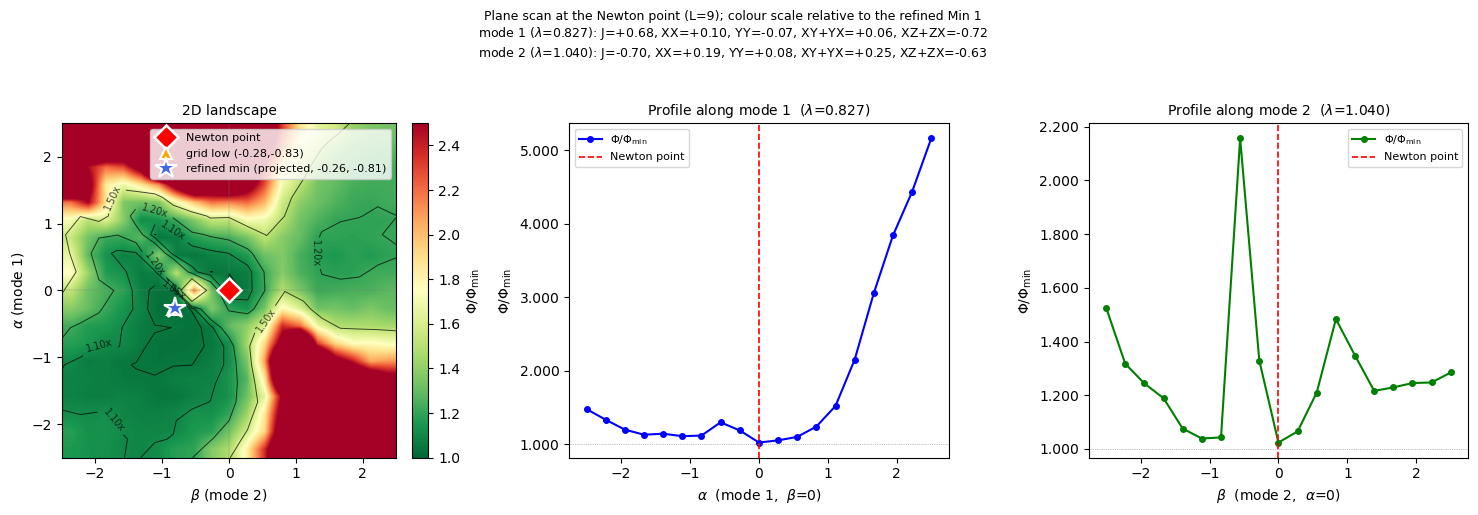

In [8]:
delta = x_min1_refined[:5] - x5_center
markers = [] if x_min1_refined is x_newton else [
    {"alpha": delta @ v1, "beta": delta @ v2, "label": f"refined min (projected, {delta @ v1:+.2f}, {delta @ v2:+.2f})"}]
plot_mode_scan(grid, alphas, alphas, evals5, evecs5, PARAMS[:5], phi_min1,
               title=f"Plane scan at the Newton point (L={L}); colour scale relative to the refined Min 1",
               center_label="Newton point", markers=markers);

## 5. Min 1 after refinement: wider scan

Downstream analyses use the refined optimum rounded to six decimals, stored in `results/minima.json`. The plane scan is repeated around it with the Hessian modes recomputed there, over a wider range ($\pm 5$, $35 \times 35$).

Stored Min 1 vs the refinement above: max |difference| = 4.1e-07
Min 1: Phi = 7.154433e-02  (1.3717x vs PRX)


5x5 Hessian (YZ+ZY = 0.001237 fixed): 0 negative eigenvalues
    mode 1: +7.2281e-01  [pos]  YY(+0.75), J(-0.55)
    mode 2: +1.0416e+00  [pos]  J(+0.71), XX(-0.46)
    mode 3: +1.1821e+00  [pos]  XZ+ZX(-0.92), YY(-0.29)
    mode 4: +1.8259e+00  [pos]  XX(-0.55), XY+YX(+0.54)
    mode 5: +1.9756e+00  [pos]  XY+YX(+0.75), XX(+0.62)


2D scan:   0%|          | 0/35 [00:00<?, ?it/s]


Wide scan minimum: Phi = 7.154433e-02 at (alpha=+0.000, beta=+0.000);  ratio to centre 1.000000
  confirmed: lowest point in the plane


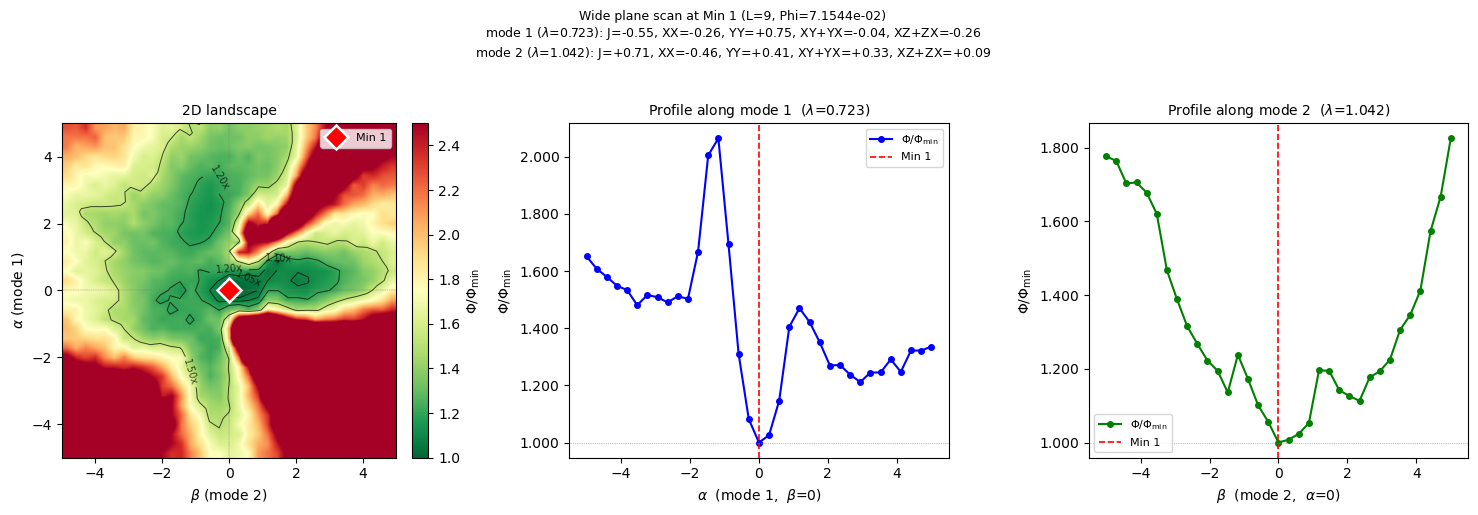

In [9]:
stored = load_json(RESULTS / "minima.json")["L9"]
x_min1 = np.array(stored["min1_canonical"])
print(f"Stored Min 1 vs the refinement above: max |difference| = {np.max(np.abs(x_min1 - x_min1_refined)):.1e}")
phi_min1 = model.phi(x_min1)
print(f"Min 1: Phi = {phi_min1:.6e}  ({phi_prx / phi_min1:.4f}x vs PRX)")

yz1 = x_min1[5]
H5_1, _ = fd_hessian(model.phi_fixed_last(yz1), x_min1[:5], eps=0.05)
evals5_1, evecs5_1 = np.linalg.eigh(H5_1)
print(f"5x5 Hessian (YZ+ZY = {yz1} fixed): {n_negative(evals5_1)} negative eigenvalues")
print(describe_modes(evals5_1, evecs5_1, PARAMS[:5]))

alphas_wide = np.linspace(-5.0, 5.0, 35)
grid_wide = scan_plane(model.phi_fixed_last(yz1), x_min1[:5], evecs5_1[:, 0], evecs5_1[:, 1], alphas_wide)
gmin, a, b = grid_argmin(grid_wide, alphas_wide)
print(f"\nWide scan minimum: Phi = {gmin:.6e} at (alpha={a:+.3f}, beta={b:+.3f});  ratio to centre {gmin / phi_min1:.6f}")
print("  confirmed: lowest point in the plane" if gmin >= phi_min1 * (1 - 5e-4) else "  *** lower point found off-centre ***")
plot_mode_scan(grid_wide, alphas_wide, alphas_wide, evals5_1, evecs5_1, PARAMS[:5], phi_min1,
               title=f"Wide plane scan at Min 1 (L={L}, Phi={phi_min1:.4e})", center_label="Min 1");

## 6. Min 2: differential evolution with J = J_PRX

This asks whether the slice $J = J_\mathrm{PRX}$ holds a second, separate basin in the 5D coupling space. DE runs with 25 individuals (popsize 5 × 5 dimensions) for up to 200 generations, then polishes with L-BFGS-B.

In [10]:
f_de = RecordingObjective(model.phi_fixed_J(J_PRX))
de = run_de(f_de, [(-5.0, 5.0)] * len(COUPLINGS), seed=42, popsize=5, maxiter=200)
c_de = de.x
x_min2 = np.concatenate([[J_PRX], c_de])
phi_min2 = de.fun

print(f"DE: Phi = {phi_min2:.6e}  ({phi_prx / phi_min2:.4f}x vs PRX),  {de.nfev} evaluations,  converged = {de.success}")
print(f"  {'coupling':>8}  {'DE':>9}  {'PRX':>9}")
for n, v, vp in zip(COUPLINGS, c_de, x_prx[1:]):
    print(f"  {n:>8}  {v:+9.4f}  {vp:+9.4f}")
print(f"  distance from the PRX couplings: {np.linalg.norm(c_de - x_prx[1:]):.4f}")

pop = 5 * len(COUPLINGS)
running = f_de.running_best()
print(f"\n  {'gen':>4}  {'evals':>6}  {'best Phi':>12}  {'vs PRX':>8}")
for gen in [1] + list(range(20, len(running) // pop + 1, 20)):
    print(f"  {gen:>4}  {gen * pop:>6}  {running[gen * pop - 1]:12.6e}  {phi_prx / running[gen * pop - 1]:7.4f}x")

DE: Phi = 7.031195e-02  (1.3958x vs PRX),  4031 evaluations,  converged = True
  coupling         DE        PRX
        XX    +1.3102    +0.8282
        YY    +0.1564    +0.0000
     XY+YX    -0.0096    +0.0000
     XZ+ZX    +0.2660    -0.2301
     YZ+ZY    -0.7049    +0.0000
  distance from the PRX couplings: 0.9999

   gen   evals      best Phi    vs PRX
     1      25  8.263973e-02   1.1875x
    20     500  7.416335e-02   1.3233x
    40    1000  7.236634e-02   1.3561x
    60    1500  7.095101e-02   1.3832x
    80    2000  7.034362e-02   1.3951x
   100    2500  7.031235e-02   1.3958x
   120    3000  7.031195e-02   1.3958x
   140    3500  7.031195e-02   1.3958x
   160    4000  7.031195e-02   1.3958x


In [11]:
x_min2_std, rot2 = to_standard_frame(x_min2)
print(f"Min 2 in the standard frame (rotated {np.degrees(rot2):.1f} deg): "
      + ", ".join(f"{n}={v:+.4f}" for n, v in zip(PARAMS, x_min2_std)))

# 5x5 Hessian over the couplings [XX, YY, XY+YX, XZ+ZX, YZ+ZY] at fixed J
H5_de, _ = fd_hessian(model.phi_fixed_J(J_PRX), c_de, eps=0.05)
evals5_de, evecs5_de = np.linalg.eigh(H5_de)
print(f"5x5 Hessian in coupling space (J = J_PRX fixed): {n_negative(evals5_de)} negative eigenvalues")
print(describe_modes(evals5_de, evecs5_de, COUPLINGS))

Min 2 in the standard frame (rotated -69.3 deg): J=+0.0639, XX=+0.3066, YY=+1.1601, XY+YX=+0.3884, XZ+ZX=+0.7534, YZ+ZY=-0.0000


5x5 Hessian in coupling space (J = J_PRX fixed): 0 negative eigenvalues
    mode 1: +5.7585e-01  [pos]  XY+YX(+0.66), XX(-0.65)
    mode 2: +6.3830e-01  [pos]  XX(+0.73), XY+YX(+0.59)
    mode 3: +1.0040e+00  [pos]  YY(-0.86), YZ+ZY(+0.48)
    mode 4: +1.4419e+00  [pos]  YZ+ZY(-0.80), XZ+ZX(-0.37)
    mode 5: +1.7692e+00  [pos]  XZ+ZX(-0.79), XY+YX(+0.38)


## 7. Min 2: plane scan and refinement

The same check as §4: a $19 \times 19$ scan ($\pm 2.5$) along the two softest coupling-space modes, then L-BFGS-B from the lowest grid point.

2D scan:   0%|          | 0/19 [00:00<?, ?it/s]

Grid minimum: Phi = 7.031195e-02 at (alpha=+0.000, beta=+0.000);  ratio to DE min 1.000000


Refined from the grid minimum: Phi = 7.03119509e-02  (DE: 7.03119509e-02; delta -1.06e-11),  |displacement| = 2.5e-06
  -> converged back within 0.01% of the DE minimum: same basin


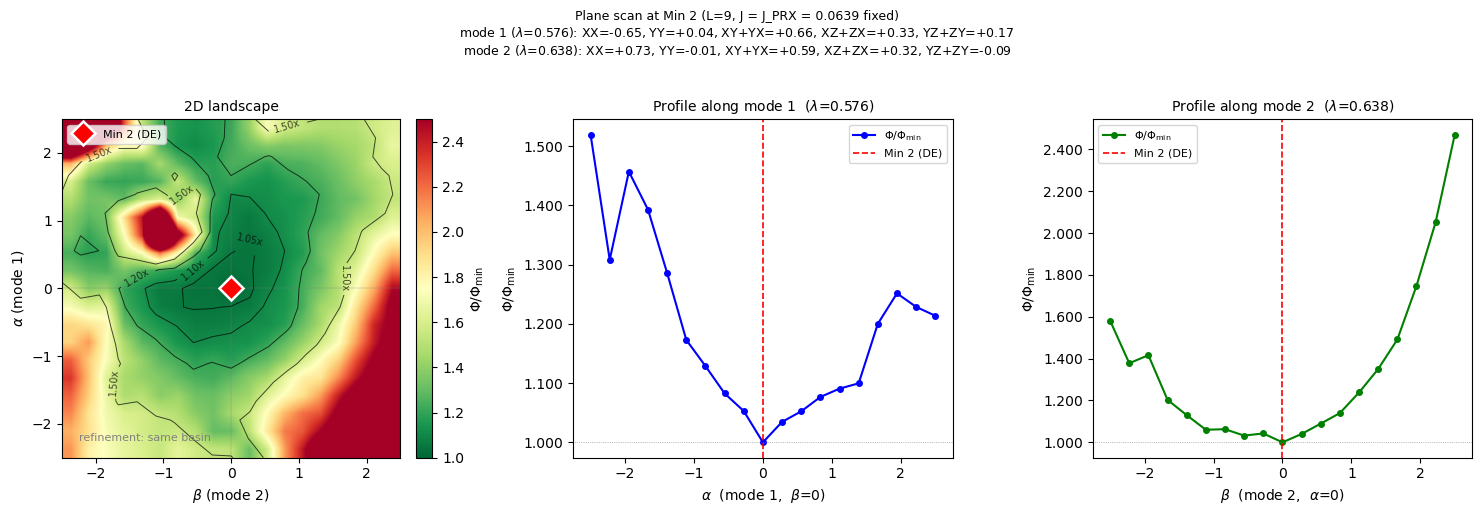

In [12]:
f_J = model.phi_fixed_J(J_PRX)
v1d, v2d = evecs5_de[:, 0], evecs5_de[:, 1]
grid_de = scan_plane(f_J, c_de, v1d, v2d, alphas)
gmin, a, b = grid_argmin(grid_de, alphas)
print(f"Grid minimum: Phi = {gmin:.6e} at (alpha={a:+.3f}, beta={b:+.3f});  ratio to DE min {gmin / phi_min2:.6f}")

refined_de = lbfgs(f_J, c_de + a * v1d + b * v2d, maxiter=1200)
print(f"Refined from the grid minimum: Phi = {refined_de.fun:.8e}  (DE: {phi_min2:.8e}; delta {refined_de.fun - phi_min2:+.2e}),"
      f"  |displacement| = {np.linalg.norm(refined_de.x - c_de):.1e}")
same_basin = refined_de.fun >= phi_min2 * (1 - 1e-4)
if same_basin:
    print("  -> converged back within 0.01% of the DE minimum: same basin")
else:
    c_de, phi_min2 = refined_de.x, refined_de.fun
    x_min2 = np.concatenate([[J_PRX], c_de])
    print("  -> lower minimum accepted")

plot_mode_scan(grid_de, alphas, alphas, evals5_de, evecs5_de, COUPLINGS, phi_min2,
               title=f"Plane scan at Min 2 (L={L}, J = J_PRX = {J_PRX:.4f} fixed)", center_label="Min 2 (DE)",
               note="refinement: same basin" if same_basin else None);

## 8. Summary

The table lists both minima in the standard frame. The fresh results are saved to `results/L9_search.json` and compared with the stored optima in `results/minima.json` that notebooks 04 and 05 use.

In [13]:
rows = {"PRX": (phi_prx, to_standard_frame(x_prx)[0]),
        "Min 1 (Newton)": (model.phi(x_min1), to_standard_frame(x_min1)[0]),
        "Min 2 (DE)": (phi_min2, to_standard_frame(x_min2)[0])}
summary = pd.DataFrame({name: {"Phi": phi, "vs PRX": phi_prx / phi, **dict(zip(PARAMS, x))}
                        for name, (phi, x) in rows.items()}).T
print(summary.to_string(formatters={"Phi": "{:.6e}".format, "vs PRX": "{:.4f}x".format,
                                    **{p: "{:+.4f}".format for p in PARAMS}}))

print(f"\nMin 1 refined vs stored: max |diff| = {np.max(np.abs(x_min1_refined - x_min1)):.1e}  (stored values are rounded to 1e-6)")
print(f"Min 2 DE vs stored:      max |diff| = {np.max(np.abs(x_min2 - np.array(stored['min2_canonical']))):.1e}")

save_json(RESULTS / "L9_search.json", {
    "L": L, "l": l, "phi_prx": phi_prx, "phi_prx_canonical": phi_prx_canonical,
    "single_coupling": {n: {k: v for k, v in r.items() if k not in ("grid", "profile")} for n, r in single.items()},
    "absolute_comparison": {"A": phi_A, "B": phi_B, "B_label": label_B, "C": phi_C, "D": phi_D},
    "newton_point": {"x": x_newton, "phi": phi_newton},
    "min1": {"x_refined": x_min1_refined, "phi_refined": refined.fun, "phi_stored": model.phi(x_min1),
             "hessian5_evals": evals5_1},
    "min2": {"x": x_min2, "phi": phi_min2, "de_nfev": de.nfev, "hessian5_evals": evals5_de},
})

                        Phi  vs PRX       J      XX      YY   XY+YX   XZ+ZX   YZ+ZY
PRX            9.813847e-02 1.0000x +0.0639 +0.8282 +0.0000 +0.0000 +0.2301 +0.0000
Min 1 (Newton) 7.154433e-02 1.3717x +0.0823 +0.5364 +0.7627 -0.4427 +0.3585 -0.0000
Min 2 (DE)     7.031195e-02 1.3958x +0.0639 +0.3066 +1.1601 +0.3884 +0.7534 -0.0000

Min 1 refined vs stored: max |diff| = 4.1e-07  (stored values are rounded to 1e-6)
Min 2 DE vs stored:      max |diff| = 2.1e-11
